# Compare the Codebook with CAP Codes

| Item | Description |
|---|---|
| Goal | Test the codebook against the human topic codes of the Comparative Agendas Project (CAP). Each matched hearing carries our primary topic and its topic group, and CAP's major topic and subtopic. The crosswalk of topic groups against CAP major topics shows where the two systems agree; many-to-one accuracy and normalized mutual information summarize the agreement at both levels against chance baselines. The codebook was built without CAP, so the comparison is a check, not a fit. |
| Input | `cap_match.parquet` from T2.3.1; the CAP hearings file and master codebook in the T2.3 Raw folder; `hearing_topics_v1.parquet` from T2.1.4 and `topic_groups.parquet` from T2.1.5. |
| Output | Under `R - Results/tables/...`: `table_cap_crosswalk` (hearing counts by group and CAP major topic), `table_cap_agreement`, and `table_cap_by_group`, each in CSV and LaTeX. One figure under `R - Results/figures/...`: `fig_cap_crosswalk`. |
| Sources | Jones, Bryan D., Frank R. Baumgartner, Sean M. Theriault, Derek A. Epp, Shruti Khandekar, Daniel Little. 2025. *Policy Agendas Project: Codebook*. Comparative Agendas Project, comparativeagendas.net. The hearing codes come from the US Congressional Hearings dataset, version 21.7, of the same project. |
| Variables | • `primary_group`: the topic group of the hearing's primary topic<br>• `majortopic`, `subtopic`: CAP's human codes for the hearing<br>• purity: the share of a group's hearings that carry the group's most common CAP major topic<br>• many-to-one accuracy: each of our categories is mapped to the CAP code it most often receives, and the share of hearings whose mapped code equals their own CAP code is counted |
| Run | The first run of 2026-08-22 ranked the human subtopic in an embedding-similarity list, a retrieval test that needed a GPU and scored an earlier benchmark taxonomy alongside. It was replaced on 2026-10-31 by this crosswalk, which needs no model; the outputs shown are from that run. The 26 topic groups stand where the first run had the 14 broad clusters. |


## Step 1. Import packages


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import normalized_mutual_info_score as nmi


## Step 2. Define file locations


In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[2]  # <pipeline>/<section>/<subfolder>/ sits three levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T - Three Step Text Analysis Pipeline/T2 - Topic Extraction and Stance Analysis/T2.3 - Validation of Topics")
NOTEBOOK_NAME = "T2.3.2 - Validation - Compare the Codebook with CAP Codes"  # the notebook filename without .ipynb
RAW_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Raw"
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
INPUT_FOLDER = SCRATCH_FOLDER / "T - Three Step Text Analysis Pipeline/T2 - Topic Extraction and Stance Analysis/T2.1 - Track 1 - Topic Extraction based on Hearing Summaries" / "Processed"
CAP_FOLDER = RAW_FOLDER / "comparative_agenda_project"
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/tables" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
MODEL_CACHE = SCRATCH_FOLDER / "cache" / "huggingface"
ENV_FILE = PROJECT_FOLDER / "T - Three Step Text Analysis Pipeline/T2 - Topic Extraction and Stance Analysis" / ".env"
for folder in (INTERIM_FOLDER, PROCESSED_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)


## Step 3. Apply the figure style


In [3]:
# Colors from the Figure Style Guide
BLACK = "#000000"
DODGER_BLUE = "#1E90FF"
SLATE_GREY = "#708090"
CYAN = "#00ACC1"
GREY = "#A6A6A8"

# Font and background
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True

# Horizontal background lines only
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5

# All text and axis lines in BLACK
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

MARGIN_INCHES = 0.5 / 2.54  # 0.5 cm between each edge of the image and the nearest element

EXPORT_DPI = 300


def fit_margins(figure, axis):
    """Move the axes so the Y-title starts 0.5 cm from the left edge, the X-title ends 0.5 cm above the bottom edge, and nothing crosses the right or top margin."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin = MARGIN_INCHES * figure.dpi
    left_shift = (margin - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
    figure.canvas.draw()
    bottom_shift = (margin - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    box = axis.get_tightbbox(renderer)
    right_over = box.x1 - (figure.bbox.width - margin)
    top_over = box.y1 - (figure.bbox.height - margin)
    if right_over > 0 or top_over > 0:
        figure.subplots_adjust(right=figure.subplotpars.right - max(right_over, 0) / figure.bbox.width,
                               top=figure.subplotpars.top - max(top_over, 0) / figure.bbox.height)
        figure.canvas.draw()
    return renderer


def legend_below(figure, axis, handles, ncol=1):
    """Place the legend with its top 0.5 cm below the X-title and its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room."""
    renderer = fit_margins(figure, axis)
    margin = MARGIN_INCHES * figure.dpi
    axis_box = axis.get_window_extent(renderer)
    center = (axis_box.x0 + axis_box.x1) / 2 / figure.bbox.width
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend = figure.legend(handles=handles, loc="upper center", bbox_to_anchor=(center, (x_title.y0 - margin) / figure.bbox.height),
                           bbox_transform=figure.transFigure, ncol=ncol, frameon=False, handlelength=1.6)
    figure.canvas.draw()
    bottom_shift = (margin - legend.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend.set_bbox_to_anchor((center, (x_title.y0 - margin) / figure.bbox.height), transform=figure.transFigure)
    figure.canvas.draw()
    return legend


def save_figure(figure, stem):
    """Export PNG, SVG, and PDF into the notebook's figure folder."""
    FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "svg", "pdf"):
        figure.savefig(FIGURE_FOLDER / f"{stem}.{extension}", dpi=EXPORT_DPI if extension == "png" else None)
    plt.close(figure)
    print(f"saved {stem}.png/.svg/.pdf")


def colorbar_below(figure, axis, mappable, label):
    """Place a horizontal colour bar where a legend would go: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge."""
    renderer = fit_margins(figure, axis)
    margin = MARGIN_INCHES * figure.dpi
    W, H = figure.bbox.width, figure.bbox.height
    x0 = axis.yaxis.label.get_window_extent(renderer).x0 / W
    bar_height = 0.018
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + (bar_height * 3 + 2 * margin / H))
    figure.canvas.draw()
    x_title = axis.xaxis.label.get_window_extent(renderer)
    bar = figure.add_axes([x0, (x_title.y0 - margin) / H - bar_height, 0.3, bar_height])
    figure.colorbar(mappable, cax=bar, orientation="horizontal", label=label)
    bar.tick_params(labelsize=8)
    bar.xaxis.label.set_size(9)
    figure.canvas.draw()
    return bar


## Step 4. Read the CAP codebook

The master codebook lists the major topics and, under each, its subtopics. Only the names are needed here.


In [4]:
majors, subs, cur = {}, {}, None
for line in (CAP_FOLDER / "master_codebook.md").read_text(encoding="latin-1").splitlines():
    mM = re.match(r"^(\d+)\.\s+(.+?)\s*$", line)
    mS = re.match(r"^(\d+):\s+(.+?)\s*$", line)
    if mM and int(mM.group(1)) <= 30:
        cur = int(mM.group(1))
        majors[cur] = mM.group(2)
    elif mS and cur is not None:
        subs[int(mS.group(1))] = {"major": cur, "name": mS.group(2)}
print(f"{len(majors)} major topics, {len(subs)} subtopics")


21 major topics, 213 subtopics


## Step 5. Build the evaluation set

Matched hearings of tiers 1 and 2 that have a primary topic and whose CAP subtopic is in the CAP codebook. Each row holds our topic and group and CAP's two codes.


In [5]:
match = pd.read_parquet(PROCESSED_FOLDER / "cap_match.parquet")
cap = pd.read_csv(CAP_FOLDER / "US-Legislative_congressional_hearings-21.7.csv", encoding="latin-1", low_memory=False, usecols=["id", "majortopic", "subtopic"])
v1 = pd.read_parquet(INPUT_FOLDER / "hearing_topics_v1.parquet")
groups = pd.read_parquet(INPUT_FOLDER / "topic_groups.parquet").set_index("topic_id")["group"]
v1["primary_group"] = v1["topic_id"].map(groups)

d = (match[match["tier"] <= 2]
     .merge(v1[["packageId", "topic_id", "primary_label", "primary_group"]], on="packageId")
     .merge(cap, left_on="cap_id", right_on="id"))
d["majortopic"] = d["majortopic"].astype(int)
d["subtopic"] = d["subtopic"].astype(int)
d = d[d["subtopic"].isin(subs)].reset_index(drop=True)
n = len(d)
print(f"evaluation set: {n:,} matched hearings; {d['primary_group'].nunique()} topic groups and {d['majortopic'].nunique()} CAP major topics represented")


evaluation set: 1,697 matched hearings; 26 topic groups and 19 CAP major topics represented


## Step 6. Cross-tabulate the groups with CAP's major topics

One row per topic group, one column per CAP major topic, each cell the number of hearings. Each group's most common CAP major topic and the share of its hearings that carry it, its purity, are the row summaries.


In [6]:
counts = pd.crosstab(d["primary_group"], d["majortopic"])
shares = counts.div(counts.sum(axis=1), axis=0) * 100
by_group = pd.DataFrame({"hearings": counts.sum(axis=1), "modal_cap_major": counts.idxmax(axis=1), "purity": shares.max(axis=1) / 100})
by_group["modal_cap_major"] = by_group["modal_cap_major"].map(lambda c: f"{c} {majors[c]}")
by_group = by_group.sort_values("hearings", ascending=False)

TABLE_FOLDER.mkdir(parents=True, exist_ok=True)
named = counts.rename(columns=lambda c: f"{c} {majors[c]}")
named.to_csv(TABLE_FOLDER / "table_cap_crosswalk.csv")
named.style.to_latex(TABLE_FOLDER / "table_cap_crosswalk.tex", hrules=True)
by_group.to_csv(TABLE_FOLDER / "table_cap_by_group.csv")
by_group.style.format({"purity": "{:.2f}"}).to_latex(TABLE_FOLDER / "table_cap_by_group.tex", hrules=True)
pd.set_option("display.width", 160)
print(by_group.round(2).to_string())
print(f"\ngroups in which more than half of the hearings share one CAP major topic: {(by_group['purity'] > 0.5).sum()} of {len(by_group)}")


                                                           hearings           modal_cap_major  purity
primary_group                                                                                        
NASA and space policy                                           187             17 Technology    0.90
Federal budgets, appropriations, and stimulus                   172             17 Technology    0.36
Energy policy, research, and clean technologies                 165                  8 Energy    0.55
Broadband infrastructure, spectrum, and universal service       113             17 Technology    0.69
Homeland and transportation security                             98         10 Transportation    0.66
Weather, satellites, and Earth observation                       95             17 Technology    0.75
Privacy and digital consumer protection                          68             17 Technology    0.29
Fossil fuels, pipelines, and fuel standards                      67               

## Step 7. Summarize the agreement at both levels

Many-to-one accuracy maps each of our categories to the CAP code it most often receives and counts the hearings whose mapped code equals their own. The baseline is the share of the single most common CAP code, what always guessing it would score. Normalized mutual information is a symmetric measure of how much one coding tells about the other, 0 for none and 1 for a one-to-one match.


In [7]:
def agreement(our_col, cap_col):
    modal = d.groupby(our_col)[cap_col].agg(lambda s: s.value_counts().index[0])
    return {"our categories": d[our_col].nunique(), "CAP categories": d[cap_col].nunique(),
            "many-to-one accuracy": (d[our_col].map(modal).to_numpy() == d[cap_col].to_numpy()).mean(),
            "baseline, most common code": d[cap_col].value_counts(normalize=True).iloc[0],
            "normalized mutual information": nmi(d[cap_col], d[our_col])}


table = pd.DataFrame({"topic groups against CAP major topics": agreement("primary_group", "majortopic"),
                      "topics against CAP subtopics": agreement("topic_id", "subtopic")}).T
table.to_csv(TABLE_FOLDER / "table_cap_agreement.csv")
table.style.format({"our categories": "{:.0f}", "CAP categories": "{:.0f}", "many-to-one accuracy": "{:.3f}", "baseline, most common code": "{:.3f}", "normalized mutual information": "{:.3f}"}).to_latex(TABLE_FOLDER / "table_cap_agreement.tex", hrules=True)
print(table.round(3).to_string())


                                       our categories  CAP categories  many-to-one accuracy  baseline, most common code  normalized mutual information
topic groups against CAP major topics            26.0            19.0                 0.612                       0.332                          0.353
topics against CAP subtopics                    108.0           126.0                 0.479                       0.094                          0.557


## Step 8. Draw the crosswalk

Rows are the 26 topic groups, ordered by their most common CAP major topic and then by size. Columns are the CAP major topics that occur. Each cell is the share of the group's hearings that CAP placed under that major topic; shares of 10 percent or more are printed.


saved fig_cap_crosswalk.png/.svg/.pdf


**Figure 1. Crosswalk of the Codebook's Topic Groups against CAP's Human-Coded Major Topics**

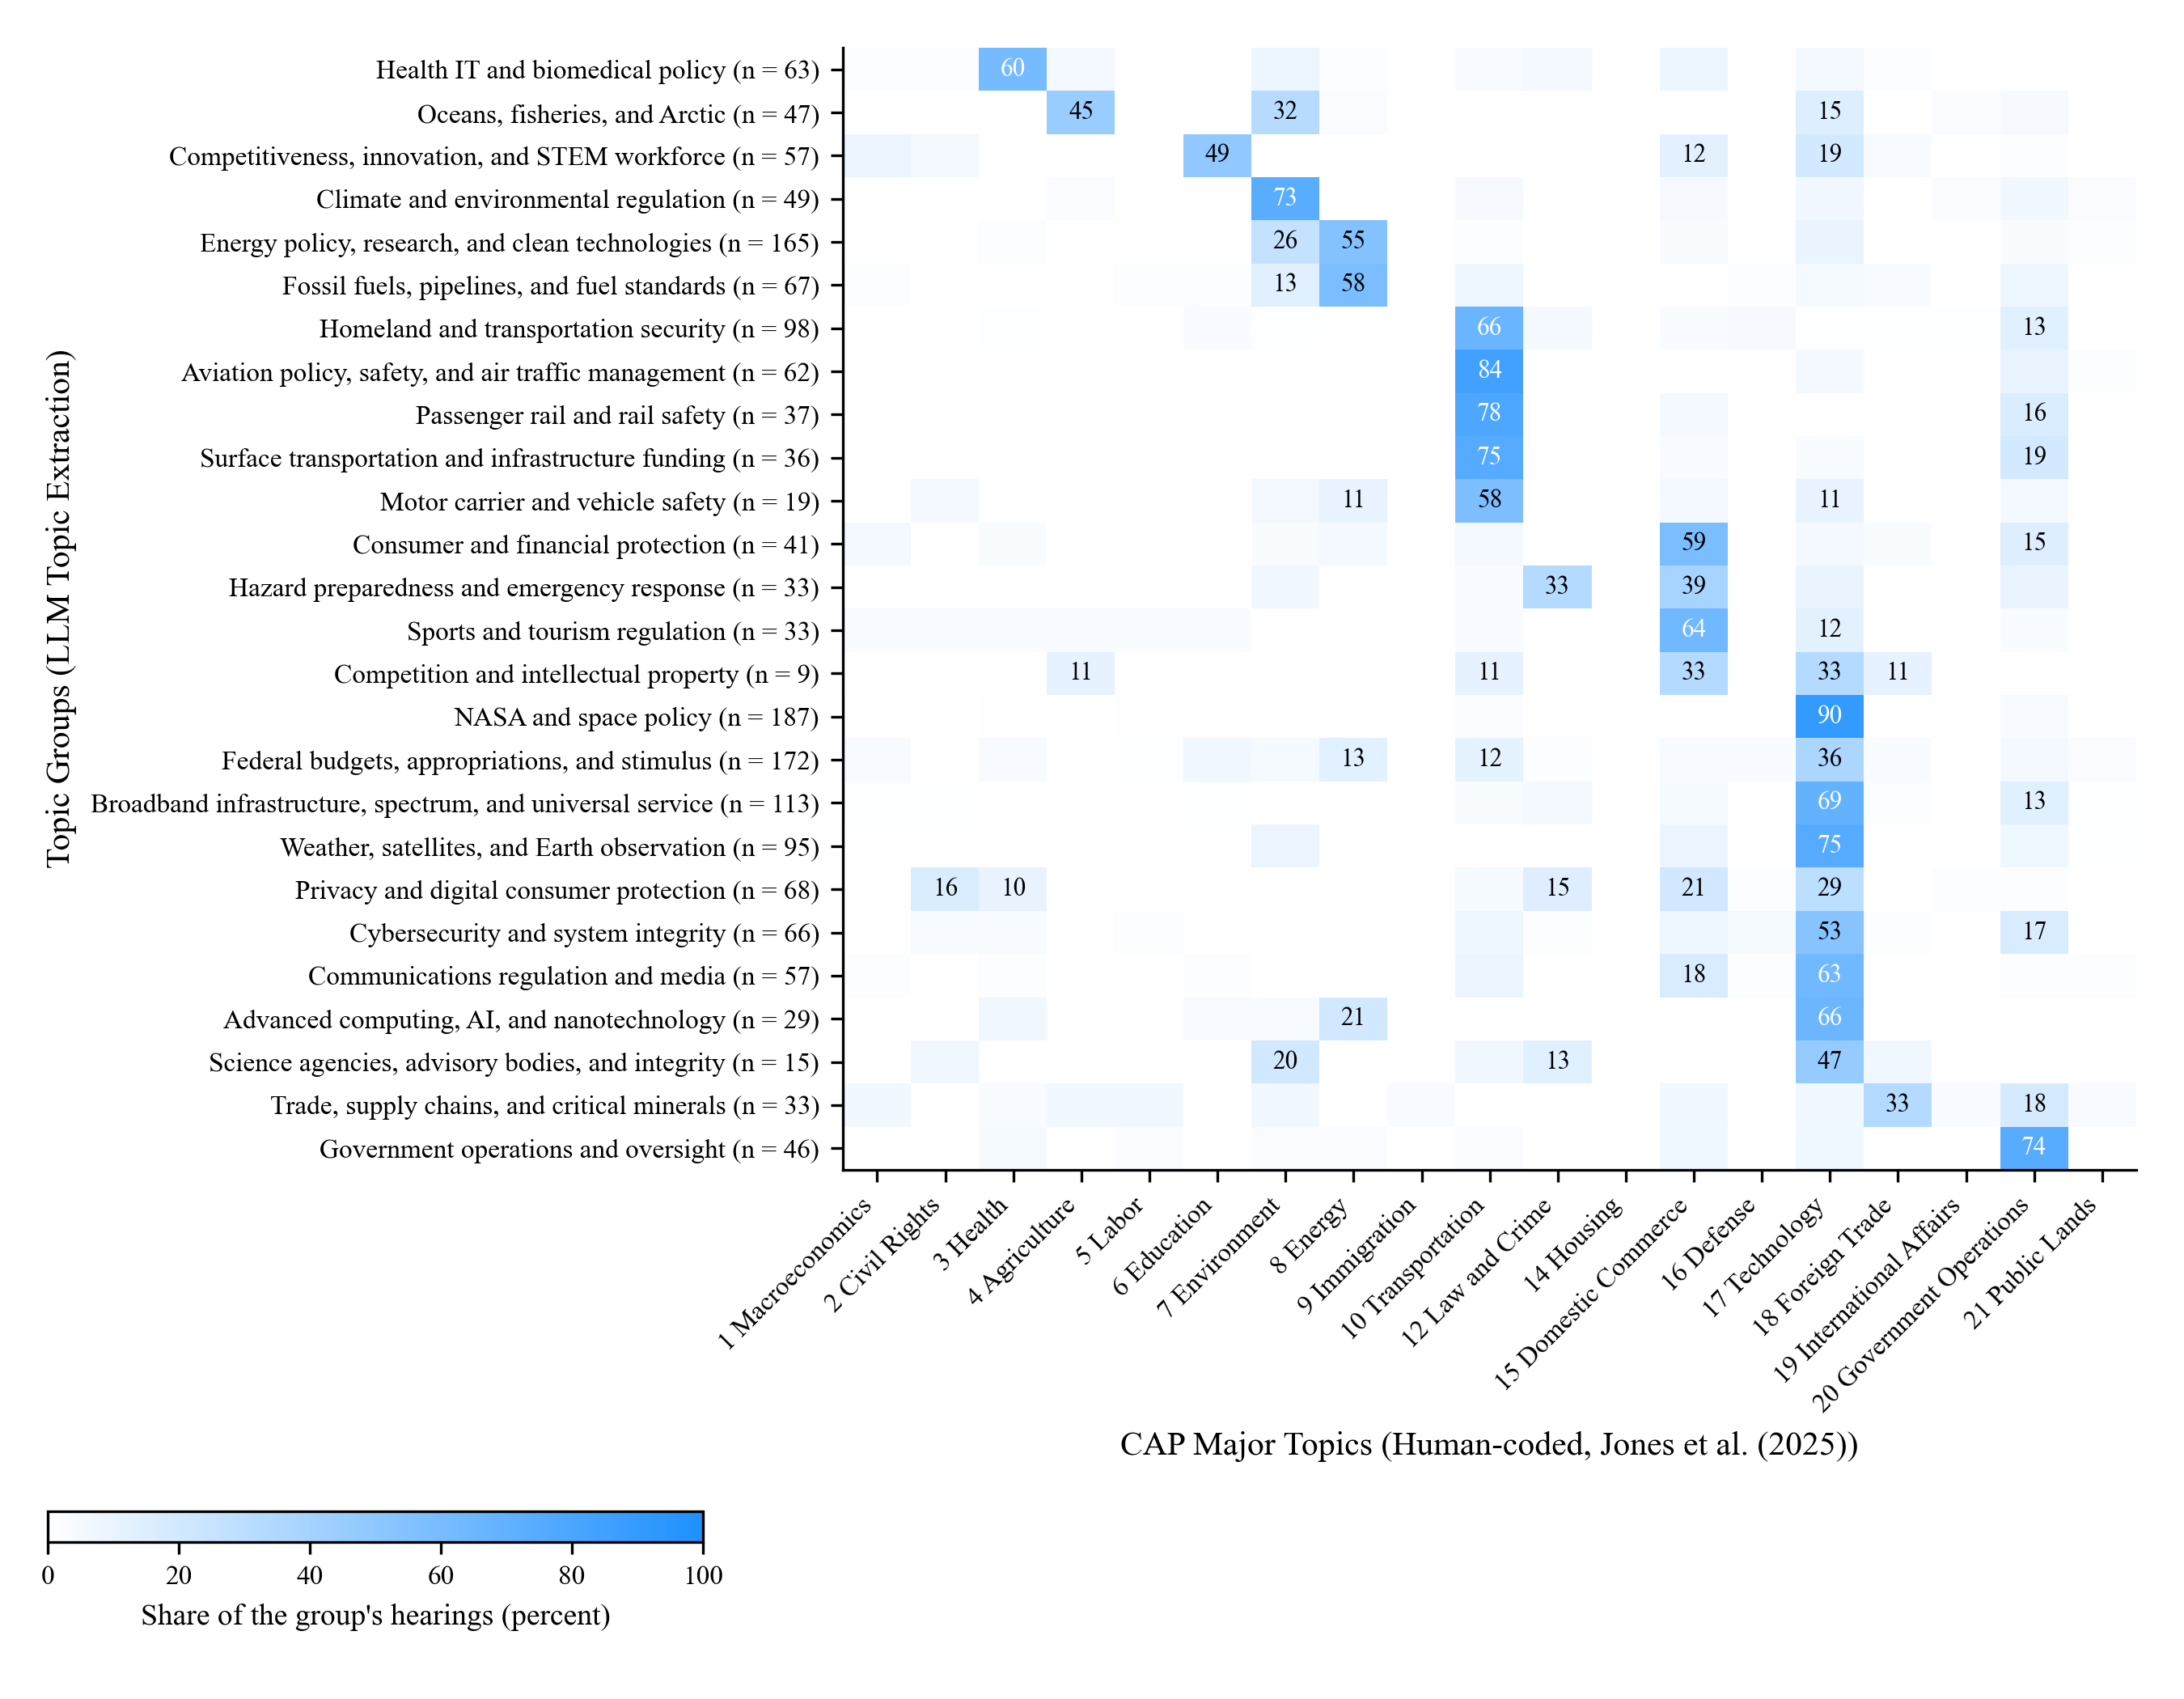

*Notes*: 1,697 hearings of the House Science and Senate Commerce committees, 1996 to 2021, matched to CAP records by T2.3.1 (tiers 1 and 2). Each hearing carries the topic group of its primary codebook topic (T2.1.4, T2.1.5) and the major topic CAP's human coders gave it. Rows are ordered by their most common CAP major topic. In 18 of 26 groups more than half of the hearings share one CAP major topic; over all hearings, 61% carry the major topic most common in their group, against 33% for always guessing the most common code. CAP's major topics are coarse: Technology covers space, telecommunications, computing, and weather alike, so a group spread over few columns can be finer than CAP rather than wrong.

*Source*: Comparative Agendas Project, US Congressional Hearings dataset 21.7 and master codebook (Jones et al. 2025); codebook and topic groups from T2.1; authors' calculations.

In [8]:
FIGURE_STEM = "fig_cap_crosswalk"
row_modal = counts.idxmax(axis=1)
row_n = counts.sum(axis=1)
order = sorted(counts.index, key=lambda r: (row_modal[r], -row_n[r]))
cols = sorted(counts.columns)
M = shares.loc[order, cols].to_numpy()

figure, axis = plt.subplots(figsize=(9, 7))
figure.subplots_adjust(left=0.42, right=1 - MARGIN_INCHES / 9, top=1 - MARGIN_INCHES / 7, bottom=0.30)
cmap = LinearSegmentedColormap.from_list("white_to_blue", ["#FFFFFF", DODGER_BLUE])
image = axis.imshow(M, cmap=cmap, vmin=0, vmax=100, aspect="auto", zorder=2)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M[i, j] >= 10:
            axis.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=7.5, color="white" if M[i, j] >= 60 else BLACK, zorder=3)
axis.set_xticks(range(len(cols)))
axis.set_xticklabels([f"{c} {majors[c]}" for c in cols], rotation=45, ha="right", fontsize=8)
axis.set_yticks(range(len(order)))
axis.set_yticklabels([f"{r} (n = {row_n[r]})" for r in order], fontsize=8)
axis.set_xticks(np.arange(-0.5, len(cols)), minor=True)
axis.set_yticks(np.arange(-0.5, len(order)), minor=True)
axis.grid(False)
axis.grid(which="minor", color="white", linewidth=0.8)
axis.tick_params(which="minor", length=0)
axis.set_xlabel("CAP Major Topics (Human-coded, Jones et al. (2025))")
axis.set_ylabel("Topic Groups (LLM Topic Extraction)")
axis.spines[["top", "right"]].set_visible(False)
colorbar_below(figure, axis, image, "Share of the group's hearings (percent)")
save_figure(figure, FIGURE_STEM)

purity = by_group["purity"]
display(Markdown("**Figure 1. Crosswalk of the Codebook's Topic Groups against CAP's Human-Coded Major Topics**"))
display(Image(filename=str(FIGURE_FOLDER / f"{FIGURE_STEM}.png"), width=900))
display(Markdown(
    f"*Notes*: {n:,} hearings of the House Science and Senate Commerce committees, 1996 to 2021, matched to CAP records by T2.3.1 (tiers 1 and 2). "
    "Each hearing carries the topic group of its primary codebook topic (T2.1.4, T2.1.5) and the major topic CAP's human coders gave it. "
    f"Rows are ordered by their most common CAP major topic. In {(purity > 0.5).sum()} of {len(purity)} groups more than half of the hearings share one CAP major topic; "
    f"over all hearings, {table.loc['topic groups against CAP major topics', 'many-to-one accuracy']:.0%} carry the major topic most common in their group, against {table.loc['topic groups against CAP major topics', 'baseline, most common code']:.0%} for always guessing the most common code. "
    "CAP's major topics are coarse: Technology covers space, telecommunications, computing, and weather alike, so a group spread over few columns can be finer than CAP rather than wrong."))
display(Markdown("*Source*: Comparative Agendas Project, US Congressional Hearings dataset 21.7 and master codebook (Jones et al. 2025); codebook and topic groups from T2.1; authors' calculations."))


## Step 9. Check the run

- Every row of the crosswalk sums to 100 percent.
- The accuracy beats its baseline at both levels.
- The tables reload.


In [9]:
assert np.allclose(shares.sum(axis=1), 100)
assert table["many-to-one accuracy"].gt(table["baseline, most common code"]).all()
back = pd.read_csv(TABLE_FOLDER / "table_cap_crosswalk.csv", index_col=0)
assert back.to_numpy().sum() == n
print(f"1) evaluation set : {n:,} matched hearings, {len(by_group)} groups, {len(cols)} CAP major topics")
print(f"2) group level    : accuracy {table.loc['topic groups against CAP major topics', 'many-to-one accuracy']:.3f} against baseline {table.loc['topic groups against CAP major topics', 'baseline, most common code']:.3f}")
print(f"3) topic level    : accuracy {table.loc['topics against CAP subtopics', 'many-to-one accuracy']:.3f} against baseline {table.loc['topics against CAP subtopics', 'baseline, most common code']:.3f}")
print(f"4) tables         : crosswalk {back.shape[0]} x {back.shape[1]} reloads and sums to the evaluation set")


1) evaluation set : 1,697 matched hearings, 26 groups, 19 CAP major topics
2) group level    : accuracy 0.612 against baseline 0.332
3) topic level    : accuracy 0.479 against baseline 0.094
4) tables         : crosswalk 26 x 19 reloads and sums to the evaluation set
